In [81]:
# Data handling
import ast
import pandas as pd
import numpy as np

# Machine learning: data splitting and evaluation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

# Text feature extraction
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

# Machine learning models
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.svm import LinearSVC

# Model performance metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Visualization
import matplotlib.pyplot as plt

### Load in the data and define X, y, train and test sets

In [82]:
df = pd.read_csv('./data/emotions_clean.csv')

X = df['clean_tokens']
y = df['emotion']

# train test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=df["emotion"]
)

### Perform Linear SVM without feature selection or tuning as a baseline

In [83]:
# Create the baseline pipeline
svm_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("model", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

# 5-fold stratified cross-validation baseline
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(
    svm_pipe,
    X,
    y,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Cross-validation Macro F1 scores:", cv_scores)
print("Mean CV Macro F1:", cv_scores.mean())
print("Std CV Macro F1:", cv_scores.std())


Cross-validation Macro F1 scores: [0.84691855 0.85089255 0.8664168  0.85656899 0.85149352]
Mean CV Macro F1: 0.8544580836106567
Std CV Macro F1: 0.006720314315960843


### Perform a grid search of SVM and TFIDF hyperparameters without feature selection


In [84]:
# 1) Tune TF-IDF settings and SVM C using CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

svm_no_fs = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        sublinear_tf=True
    )),
    ("model", LinearSVC(
        max_iter=5000,
        random_state=42
    ))
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2, 3],
    "tfidf__max_df": [0.90, 0.95],
    "model__C": [0.1, 1, 10]
}

svm_grid = GridSearchCV(
    estimator=svm_no_fs,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X, y)

print("Best parameters without feature selection:", svm_grid.best_params_)
print("Best CV Macro F1 without feature selection:", svm_grid.best_score_)

best_no_fs = svm_grid.best_estimator_

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters without feature selection: {'model__C': 1, 'tfidf__max_df': 0.95, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
Best CV Macro F1 without feature selection: 0.8544580836106567


### Use tuned model to search over a range of selected features

In [85]:
# Create SVM pipeline with Chi-squared feature selection
svm_fs_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("feature_selection", SelectKBest(
        score_func=chi2
    )),
    ("model", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

# define parameter grid for selected features
param_grid_fs = {
    'feature_selection__k': [500, 1000, 2500, 5000, 10000],
    'model__C': [0.1, 1, 10]
}

In [86]:
# Run grid search and examine results
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

svm_fs_grid = GridSearchCV(
    svm_fs_pipe,
    param_grid_fs,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

svm_fs_grid.fit(X_train, y_train)

print("Best parameters:", svm_fs_grid.best_params_)
print("Best CV Macro F1:", svm_fs_grid.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


/home/mark/OMDS/.venv/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=10000 is greater than n_features=9004. All the features will be returned.
  warnings.warn(
/home/mark/OMDS/.venv/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=10000 is greater than n_features=8958. All the features will be returned.
  warnings.warn(
/home/mark/OMDS/.venv/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=10000 is greater than n_features=8981. All the features will be returned.
  warnings.warn(
/home/mark/OMDS/.venv/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=10000 is greater than n_features=9071. All the features will be returned.
  warnings.warn(
/home/mark/OMDS/.venv/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=10000 is greater than n_fe

Best parameters: {'feature_selection__k': 2500, 'model__C': 1}
Best CV Macro F1: 0.8564350510991414


### Now that best hyperparameters and number of features have been selected, run SVM, TFIDF, and SelectKBest() with best parameters

In [89]:
# Define pipeline with the best parameters from the previous CV searches
best_ngram = svm_grid.best_params_["tfidf__ngram_range"]
best_min_df = svm_grid.best_params_["tfidf__min_df"]
best_max_df = svm_grid.best_params_["tfidf__max_df"]
best_k = svm_fs_grid.best_params_["feature_selection__k"]
best_c = svm_fs_grid.best_params_["model__C"]

svm_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=best_ngram,
        min_df=best_min_df,
        max_df=best_max_df,
        sublinear_tf=True
    )),
    ("feature_selection", SelectKBest(
        score_func=chi2,
        k=best_k
    )),
    ("model", LinearSVC(
        C=best_c,
        max_iter=5000,
        random_state=42
    ))
])

# Fit once so we can inspect the selected features and scores
svm_pipe.fit(X, y)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('tfidf', ...), ('feature_selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",'unicode'
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


In [90]:
# Fit model, make predictions, and evaluate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    svm_pipe,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Cross-validation Macro F1 scores:", scores)
print("Mean CV Macro F1:", scores.mean())
print("Std CV Macro F1:", scores.std())


Cross-validation Macro F1 scores: [0.86264831 0.85552968 0.85681372 0.85077499 0.85640856]
Mean CV Macro F1: 0.8564350510991414
Std CV Macro F1: 0.003784301071224657


### Examine features selected by feature selection process

In [91]:
# Examine feature selection
tfidf = svm_pipe.named_steps['tfidf']
selector = svm_pipe.named_steps['feature_selection']

print("Original TF-IDF features:", len(tfidf.get_feature_names_out()))
print("Selected features:", selector.get_support().sum())

Original TF-IDF features: 13527
Selected features: 2500


                feature       score
304              amazed  563.511992
2139            curious  483.412582
5963          impressed  469.830507
3455        feel amazed  439.667911
3580       feel curious  364.135984
11391         surprised  357.657700
3722         feel funny  331.391722
4903              funny  319.217463
10506           shocked  287.570557
4150     feel surprised  267.589469
8658        overwhelmed  254.675743
13139             weird  248.470997
2294               daze  227.237851
3813     feel impressed  226.190367
11462       sympathetic  224.732870
3955   feel overwhelmed  214.760166
4256         feel weird  201.562579
5744              horny  197.892705
4082       feel shocked  196.033014
11112           strange  194.920158
8438          nostalgic  190.639691
8230            naughty  172.098272
7683              loyal  168.498692
4153   feel sympathetic  167.065461
2384           delicate  163.812313
4715               fond  162.244512
11214           stunned  161

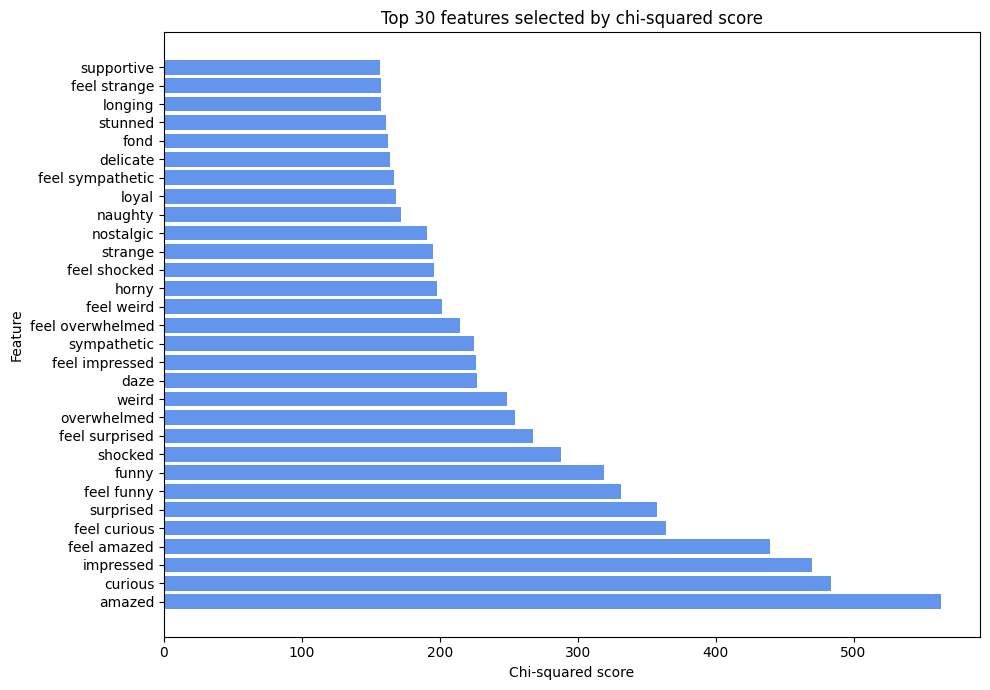

In [95]:
# Examine highest scoring features
feature_scores = pd.DataFrame({
    'feature': tfidf.get_feature_names_out(),
    'score': selector.scores_
})

feature_scores_top = feature_scores.sort_values('score', ascending=False).head(30)
print(feature_scores_top)

plt.figure(figsize=(10, 7))
plt.barh(feature_scores_top['feature'][::-1], feature_scores_top['score'][::-1], color='cornflowerblue')
plt.title('Top 30 features selected by chi-squared score')
plt.xlabel('Chi-squared score')
plt.ylabel('Feature')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### Experiment with different ngram ranges

In [93]:
# Compare TF-IDF n-gram ranges using 5-fold cross-validation
ngram_ranges = [(1, 1), (1, 2), (1, 3), (2, 2), (1, 4)]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for ngram_range in ngram_ranges:
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=ngram_range,
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("feature_selection", SelectKBest(
                score_func=chi2,
                k=2500
            )),
        ("model", LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    results.append({
        "ngram_range": ngram_range,
        "mean_f1_macro": scores.mean(),
        "std_f1_macro": scores.std(),
        "fold_scores": scores
    })

    print(f"ngram_range={ngram_range} -> mean F1_macro={scores.mean():.4f} ± {scores.std():.4f}")

results_df = pd.DataFrame(results)
print("\nComparison summary:")
print(results_df.sort_values("mean_f1_macro", ascending=False).reset_index(drop=True))


ngram_range=(1, 1) -> mean F1_macro=0.8366 ± 0.0098
ngram_range=(1, 2) -> mean F1_macro=0.8564 ± 0.0038
ngram_range=(1, 3) -> mean F1_macro=0.8584 ± 0.0050
ngram_range=(2, 2) -> mean F1_macro=0.6735 ± 0.0082
ngram_range=(1, 4) -> mean F1_macro=0.8592 ± 0.0047

Comparison summary:
  ngram_range  mean_f1_macro  std_f1_macro  \
0      (1, 4)       0.859216      0.004656   
1      (1, 3)       0.858420      0.005013   
2      (1, 2)       0.856435      0.003784   
3      (1, 1)       0.836637      0.009755   
4      (2, 2)       0.673492      0.008213   

                                         fold_scores  
0  [0.863433028507114, 0.8654362926627547, 0.8565...  
1  [0.8633159305726954, 0.8654362926627547, 0.855...  
2  [0.8626483107211648, 0.855529677744269, 0.8568...  
3  [0.8539168645775351, 0.8355562852479467, 0.823...  
4  [0.6683779675371518, 0.6852635961770286, 0.662...  


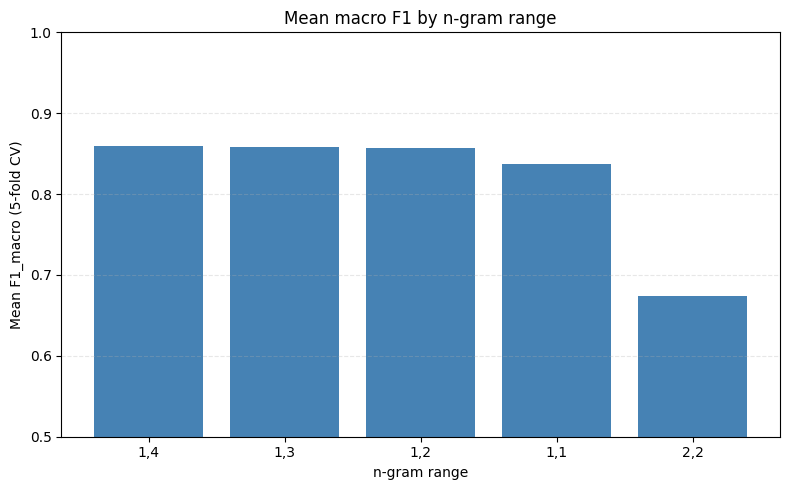

In [94]:
# Plot the cross-validation comparison by n-gram range
plot_df = results_df.sort_values("mean_f1_macro", ascending=False).copy()
plot_df["ngram_range_label"] = plot_df["ngram_range"].apply(lambda x: f"{x[0]},{x[1]}")

plt.figure(figsize=(8, 5))
plt.bar(plot_df["ngram_range_label"], plot_df["mean_f1_macro"], color="steelblue")
plt.title("Mean macro F1 by n-gram range")
plt.xlabel("n-gram range")
plt.ylabel("Mean F1_macro (5-fold CV)")
plt.ylim(0.5, 1.0)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### the best model used individual words, word pairs, and groups of three consecutive words

### after adding feature selection, the best model also includes groups of four consecutive words (phrases)

### Try modelling without "feel" to compare

In [98]:
# Model pipeline that omits the word 'feel' from TF-IDF features
vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 4),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    token_pattern=r"(?u)\b(?!feel\b)\w+\b"
)

svm_feel_removed_pipe = Pipeline([
    ("tfidf", vectorizer),
    ("feature_selection", SelectKBest(score_func=chi2, k=2500)),
    ("model", LinearSVC(C=1.0, max_iter=5000, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
feel_removed_scores = cross_val_score(
    svm_feel_removed_pipe,
    X,
    y,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Cross-validation Macro F1 scores (without 'feel'):", feel_removed_scores)
print("Mean CV Macro F1 (without 'feel'):", feel_removed_scores.mean())
print("Std CV Macro F1 (without 'feel'):", feel_removed_scores.std())


Cross-validation Macro F1 scores (without 'feel'): [0.84208821 0.84624477 0.86292919 0.84389072 0.8443437 ]
Mean CV Macro F1 (without 'feel'): 0.8478993204395948
Std CV Macro F1 (without 'feel'): 0.007630398376977497


### Experiment with negation

In [97]:
X_neg = df['clean_tokens_neg']
y = df['emotion']

# train test split
X_train_neg, X_test_neg, y_train, y_test = train_test_split(
    X_neg,
    y,
    test_size=0.2,
    random_state=42,
    stratify=df["emotion"]
)

In [101]:
# Evaluate the tuned model on the test set with both original and negated text
svm_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=best_ngram,
        min_df=best_min_df,
        max_df=best_max_df,
        sublinear_tf=True
    )),
    ("feature_selection", SelectKBest(
        score_func=chi2,
        k=best_k
    )),
    ("model", LinearSVC(
        C=best_c,
        max_iter=5000,
        random_state=42
    ))
])

# Original text
svm_pipe.fit(X_train, y_train)
y_pred = svm_pipe.predict(X_test)

print("Original text test-set results:")
print(classification_report(y_test, y_pred, digits=3))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average='macro'))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))



Original text test-set results:
              precision    recall  f1-score   support

       anger      0.927     0.877     0.901       432
        fear      0.895     0.907     0.901       387
         joy      0.878     0.941     0.909      1072
        love      0.841     0.709     0.769       261
     sadness      0.940     0.941     0.941       933
    surprise      0.865     0.722     0.787       115

    accuracy                          0.902      3200
   macro avg      0.891     0.850     0.868      3200
weighted avg      0.901     0.902     0.900      3200

Accuracy: 0.9015625
Balanced accuracy: 0.8495207780649334
Macro F1: 0.8679283303272435
Confusion matrix:
[[ 379    5   25    4   19    0]
 [   8  351    9    1   14    4]
 [  11    2 1009   29   15    6]
 [   1    1   66  185    8    0]
 [  10    9   32    1  878    3]
 [   0   24    8    0    0   83]]


In [100]:
# Negated text
svm_pipe_neg = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=best_ngram,
        min_df=best_min_df,
        max_df=best_max_df,
        sublinear_tf=True
    )),
    ("feature_selection", SelectKBest(
        score_func=chi2,
        k=best_k
    )),
    ("model", LinearSVC(
        C=best_c,
        max_iter=5000,
        random_state=42
    ))
])

svm_pipe_neg.fit(X_train_neg, y_train)
y_pred_neg = svm_pipe_neg.predict(X_test_neg)

print("\nNegated text test-set results:")
print(classification_report(y_test, y_pred_neg, digits=3))
print("Accuracy:", accuracy_score(y_test, y_pred_neg))
print("Balanced accuracy:", balanced_accuracy_score(y_test, y_pred_neg))
print("Macro F1:", f1_score(y_test, y_pred_neg, average='macro'))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_neg))



Negated text test-set results:
              precision    recall  f1-score   support

       anger      0.924     0.870     0.896       432
        fear      0.888     0.899     0.893       387
         joy      0.874     0.941     0.906      1072
        love      0.821     0.705     0.759       261
     sadness      0.940     0.931     0.936       933
    surprise      0.847     0.722     0.779       115

    accuracy                          0.897      3200
   macro avg      0.882     0.845     0.862      3200
weighted avg      0.896     0.897     0.895      3200

Accuracy: 0.8965625
Balanced accuracy: 0.844825094347556
Macro F1: 0.8616556335076285
Confusion matrix:
[[ 376    6   22    6   22    0]
 [   9  348   12    1   12    5]
 [   9    2 1009   32   15    5]
 [   1    2   68  184    6    0]
 [  12   10   36    1  869    5]
 [   0   24    8    0    0   83]]


### Including negation appears to have made predicting every emotion worse across the board, disconfirming my hypothesis that negative emotions would benefit from negation terms